# Phase 6 — Daily report

**Purpose.** One run, one page. This notebook calls every phase of the lab
in order and states what your rules allow today.

| Step | Question | Built in |
|---|---|---|
| 1 | Is the market regime gate open? | Phase 4 |
| 2 | Which stocks pass the scan, and in which themes? | Phase 4 |
| 3 | What does my trade log say about my edge? | Phase 2 |
| 4 | What risk per trade does the evidence support? | Phase 3 |
| 5 | Which two positions, and how many shares? | Phase 5 |
| 6 | What range of futures follows from that risk? | Phases 1 and 3 |

**How to use.** Edit the `KEY IN HERE` cell, then `Kernel ▸ Restart & Run All`.
The report is also saved in the `reports` folder.

**Read this first.** The default trade log is the made-up sample. The setup
score is untested. The report applies the lab's rules to the lab's
assumptions. It is a study tool, not advice and not an instruction to trade.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from IPython.display import Markdown, display

import lab_style as ls
import daily_report as dr

ls.use_lab_style()
dollars = FuncFormatter(lambda v, _: f"${v:,.0f}")

In [2]:
# ============================================================
# KEY IN HERE
# ============================================================
cfg = dr.Config(
    equity         = 2000,                    # account in $
    trade_log      = "sample_trade_log.csv",  # your own log goes here
    refresh        = False,                   # True = download fresh prices
    rule_risk_pct  = 0.01,                    # your rule: 1R = 1%
    stop_adr       = 0.5,                     # stop distance in ADR
    gap_budget_pct = 0.03,                    # loss accepted on a one-ADR gap
    drawdown_limit = 0.30,                    # drawdown you do not accept...
    max_chance     = 0.10,                    # ...with more than this chance
)

## Run every phase

In [3]:
r = dr.run(cfg)

print(f"Prices to {r['as_of']}   account ${cfg.equity:,.0f}   "
      f"trade log: {cfg.trade_log} ({len(r['log'])} trades)\n")
print(f"VERDICT: {dr.overall(r['verdict'])}")
for status, text in r["verdict"]:
    print(f"  {status:8s} {text}")

Prices to 2026-11-13   account $2,000   trade log: sample_trade_log.csv (40 trades)

VERDICT: STOP
  STOP     Regime gate closed. Your rule allows no new breakout entries.
  CAUTION  P(edge > 0) = 62% from 40 trades. Evidence supports half risk.
  CAUTION  Supported risk 0.3% per trade ($6); your rule is 1.0%.
  CAUTION  Allocation, as an exercise only: CELH x7, CVNA x3.


The verdict is `STOP` if any line says STOP, otherwise `CAUTION` if any
line says CAUTION, otherwise `GO`.

## The dashboard

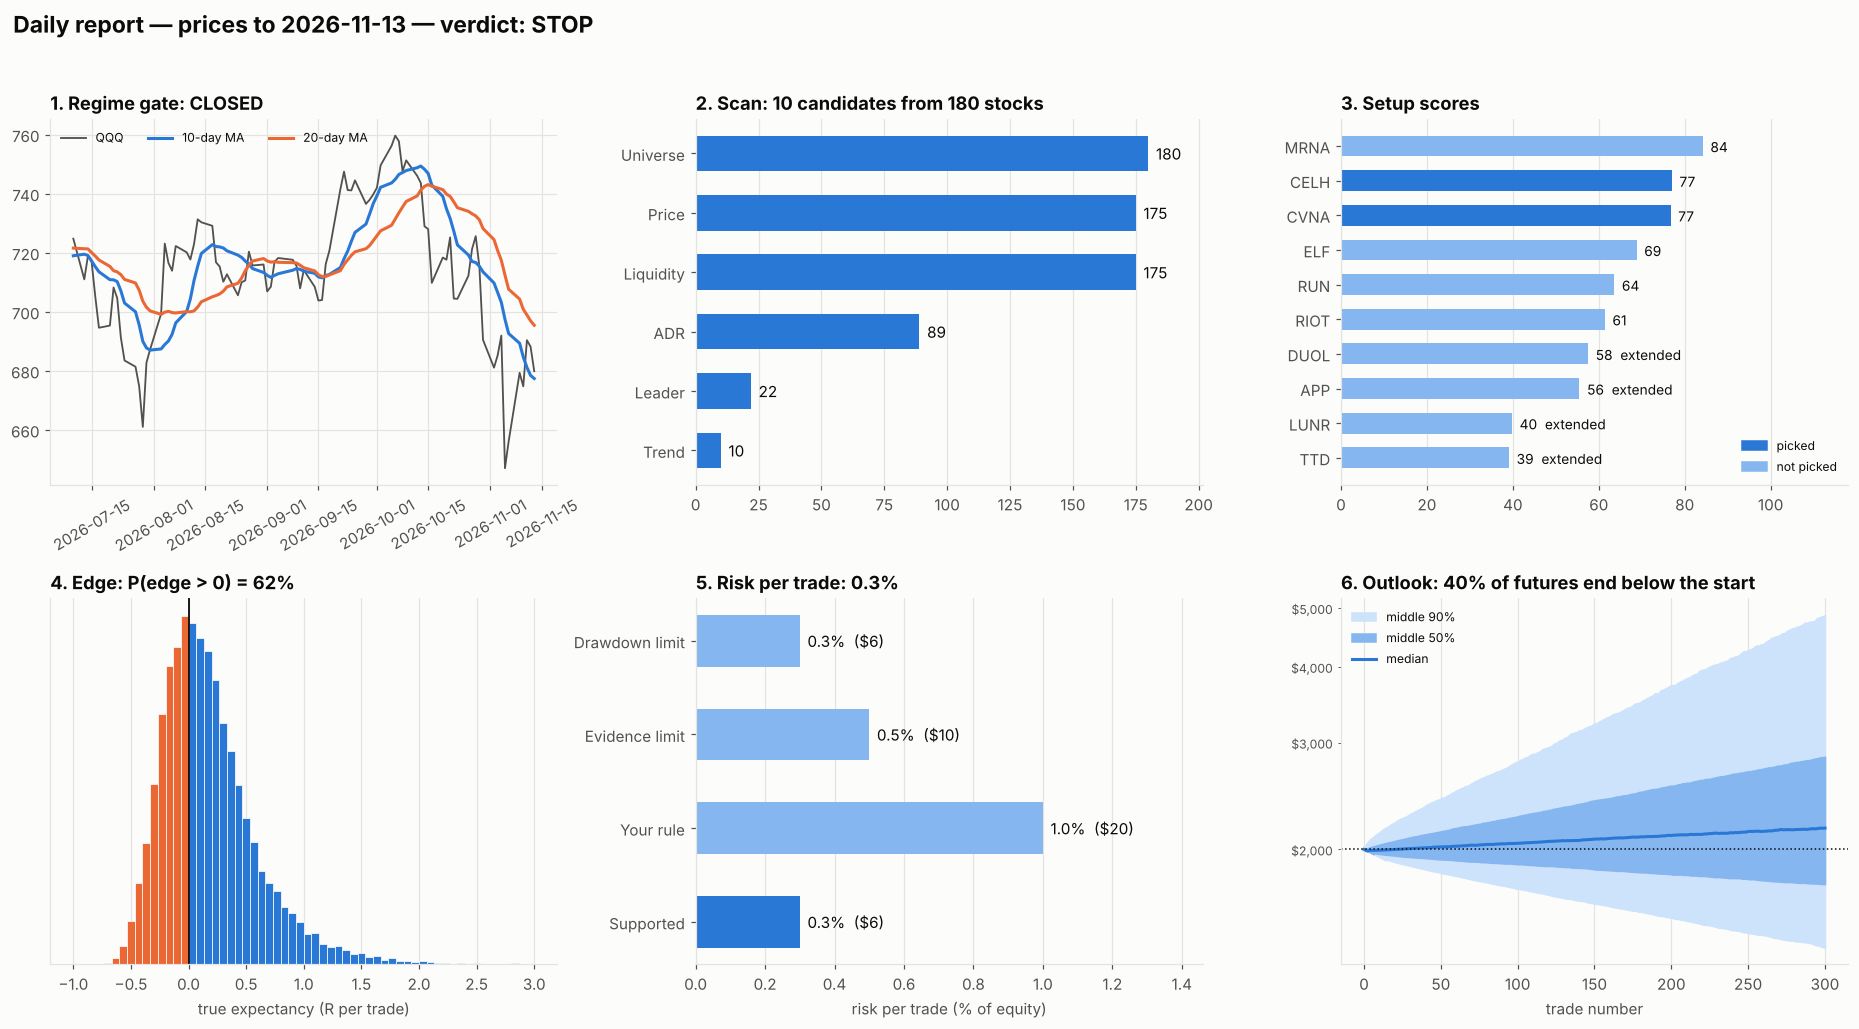

In [4]:
scan, risk = r["scan"], r["risk"]
close = r["prices"]["Close"]
picked = list(r["orders"].index) if r["orders"] is not None else []

fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))

# 1. Market regime
ax = axes[0, 0]
px = close["QQQ"].iloc[-90:]
ax.plot(px.index, px, color=ls.TEXT_SOFT, lw=1.2, label="QQQ")
ax.plot(px.index, close["QQQ"].rolling(10).mean().iloc[-90:], color=ls.BLUE, label="10-day MA")
ax.plot(px.index, close["QQQ"].rolling(20).mean().iloc[-90:], color=ls.ORANGE, label="20-day MA")
ax.set_title(f"1. Regime gate: {'OPEN' if scan['regime']['gate_open'] else 'CLOSED'}")
ax.legend(loc="upper left", ncol=3, fontsize=8)
ax.tick_params(axis="x", labelrotation=30)

# 2. Filter funnel
ax = axes[0, 1]
labels = list(scan["counts"])[::-1]
values = [scan["counts"][k] for k in labels]
ax.barh(labels, values, color=ls.BLUE, height=0.6)
for y, v in enumerate(values):
    ax.annotate(str(v), (v, y), textcoords="offset points", xytext=(5, -4), color=ls.TEXT)
ax.set_xlim(0, max(values) * 1.12); ax.grid(axis="y", visible=False)
ax.set_title(f"2. Scan: {values[0]} candidates from {values[-1]} stocks")

# 3. Candidate scores
ax = axes[0, 2]
cands = scan["candidates"]
order = list(cands.index)[::-1]
colors = [ls.BLUE if t in picked else ls.BLUE_BAND_INNER for t in order]
ax.barh(order, cands.loc[order, "score"], color=colors, height=0.6)
for y, t in enumerate(order):
    note = f"{cands.loc[t, 'score']:.0f}"
    if cands.loc[t, "ext_adr"] > cfg.max_ext_adr:
        note += "  extended"
    ax.annotate(note, (cands.loc[t, "score"], y), textcoords="offset points",
                xytext=(5, -4), color=ls.TEXT, fontsize=9)
ax.set_xlim(0, 118); ax.grid(axis="y", visible=False)
ax.set_title("3. Setup scores")
ax.legend(handles=[Patch(color=ls.BLUE, label="picked"),
                   Patch(color=ls.BLUE_BAND_INNER, label="not picked")],
          loc="lower right", fontsize=8)

# 4. Belief about the edge
ax = axes[1, 0]
exp = r["edge"]["expectancy_R"]
bins = np.linspace(-1, 3, 61)
_, edges, patches = ax.hist(exp, bins=bins, color=ls.BLUE, edgecolor=ls.SURFACE, linewidth=0.5)
for patch, left in zip(patches, edges[:-1]):
    if left < 0:
        patch.set_facecolor(ls.ORANGE)
ax.axvline(0, color=ls.TEXT, lw=1.2)
ax.set_yticks([]); ax.set_xlabel("true expectancy (R per trade)")
ax.set_title(f"4. Edge: P(edge > 0) = {risk['p_positive']:.0%}")

# 5. Risk limits
ax = axes[1, 1]
names = ["Supported", "Your rule", "Evidence limit", "Drawdown limit"]
vals = [100 * risk[k] for k in ["supported", "rule_risk", "evidence_risk", "drawdown_limit_risk"]]
ax.barh(names, vals, color=[ls.BLUE] + [ls.BLUE_BAND_INNER] * 3, height=0.55)
for y, v in enumerate(vals):
    ax.annotate(f"{v:.1f}%  (${cfg.equity * v / 100:,.0f})", (v, y),
                textcoords="offset points", xytext=(5, -4), color=ls.TEXT)
ax.set_xlim(0, max(vals) * 1.45 + 0.01); ax.grid(axis="y", visible=False)
ax.set_xlabel("risk per trade (% of equity)")
ax.set_title(f"5. Risk per trade: {risk['supported']:.1%}")

# 6. Outlook
ax = axes[1, 2]
if r["equity"] is not None:
    x = np.arange(r["equity"].shape[1])
    p5, p25, p50, p75, p95 = np.percentile(r["equity"], [5, 25, 50, 75, 95], axis=0)
    ax.fill_between(x, p5, p95, color=ls.BLUE_BAND_OUTER, label="middle 90%")
    ax.fill_between(x, p25, p75, color=ls.BLUE_BAND_INNER, label="middle 50%")
    ax.plot(x, p50, color=ls.BLUE, label="median")
    ax.axhline(cfg.equity, color=ls.TEXT, lw=1, ls=":")
    ax.set_yscale("log"); ax.yaxis.set_major_formatter(dollars)
    ax.yaxis.set_minor_formatter(dollars); ax.tick_params(axis="y", which="minor", labelsize=8)
    ax.set_xlabel("trade number"); ax.legend(loc="upper left", fontsize=8)
    ax.set_title(f"6. Outlook: {r['outlook']['p_below_start']:.0%} of futures end below the start")
else:
    ax.axis("off"); ax.set_title("6. Outlook: no risk supported")

fig.suptitle(f"Daily report — prices to {r['as_of']} — verdict: {dr.overall(r['verdict'])}",
             fontsize=15, fontweight="bold", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

## The written report

In [5]:
display(Markdown(dr.to_markdown(r)))

# Daily report — prices to 2026-11-13

Account $2,000 · trade log `sample_trade_log.csv` (40 trades) · study tool, not advice.

## Verdict: STOP

- **STOP** — Regime gate closed. Your rule allows no new breakout entries.
- **CAUTION** — P(edge > 0) = 62% from 40 trades. Evidence supports half risk.
- **CAUTION** — Supported risk 0.3% per trade ($6); your rule is 1.0%.
- **CAUTION** — Allocation, as an exercise only: CELH x7, CVNA x3.

## 1. Market regime

QQQ close 679.89, 10-day MA 677.40, 20-day MA 695.45. Gate closed.

## 2. Scan

Universe 180 → Price 175 → Liquidity 175 → ADR 89 → Leader 22 → Trend 10

|      |   price |   adr_pct |   mom_rank |   ext_adr |   tightness |   score | theme   |
|:-----|--------:|----------:|-----------:|----------:|------------:|--------:|:--------|
| MRNA |  223.37 |     10.2  |     100    |     -0.78 |        0.7  |    84.2 | solo    |
| CELH |   32.42 |      4.74 |      95.56 |      0.53 |        0.8  |    77   | solo    |
| CVNA |   72.37 |      5.12 |      98.33 |     -0.24 |        0.94 |    76.7 | solo    |
| ELF  |  117.98 |      4.63 |      98.89 |      0.57 |        0.87 |    68.8 | solo    |
| RUN  |    8.63 |      7.48 |      92.22 |     -0.58 |        0.92 |    63.6 | solo    |
| RIOT |   17.52 |      9.35 |      92.78 |      0.87 |        0.82 |    61.4 | T5      |
| DUOL |  165.31 |      5.88 |      97.78 |      1.25 |        1.07 |    57.5 | solo    |
| APP  |  409.1  |      5.42 |     100    |      3.08 |        1.04 |    55.5 | solo    |
| LUNR |   13    |      9.25 |      91.11 |      1.8  |        1.14 |    39.8 | T2      |
| TTD  |   15.68 |      5.04 |      98.89 |      2.09 |        1.52 |    39.1 | solo    |

## 3. Edge (from the trade log)

|              |    5% |   median |   95% |
|:-------------|------:|---------:|------:|
| win_rate     |  0.13 |     0.21 |  0.3  |
| avg_win_R    |  2.89 |     4.23 |  7.22 |
| expectancy_R | -0.36 |     0.11 |  0.98 |

P(edge > 0) = 62%, between 60% and 90%. Stay at half risk.

## 4. Risk per trade

| Limit | Risk per trade |
|---|---|
| Drawdown limit (P(drawdown ≥ 30%) ≤ 10%) | 0.3% |
| Evidence limit | 0.5% |
| Your rule | 1.0% |
| **Supported (smallest)** | **0.3%** |

## 5. Allocation

|      |   price |   stop_price |   shares |   cost |   risk_R |   score | theme   |   risk $ |
|:-----|--------:|-------------:|---------:|-------:|---------:|--------:|:--------|---------:|
| CELH |   32.42 |        31.65 |        7 | 226.94 |     0.9  |    77   | solo    |     5.38 |
| CVNA |   72.37 |        70.52 |        3 | 217.11 |     0.93 |    76.7 | solo    |     5.56 |

Total cost $444.05 (22% of the account), total risk $10.94.

The regime gate is closed, so this allocation is an exercise.

## 6. Outlook over 300 trades at the supported risk

- Final account: 5th percentile $1,378, median $2,169, 95th percentile $4,870
- Chance of ending below the start: 40%
- Median worst drawdown: 11%; chance of 30% or more: 7%

## Limits of this report

- The setup score is untested as a predictor of returns.
- The prior on the edge is borrowed from other traders' statistics.
- Prices are daily closes; entry and stop rules need intraday data.
- No costs, slippage, earnings dates or news. See `MANUAL.md`, section 6.


## Save

In [6]:
for path in dr.save(r, fig):
    print("Saved", path.relative_to(path.parent.parent))

Saved reports/daily_report_2026-11-13.md
Saved reports/daily_report_2026-11-13.png


## How to read the verdict

| Line | STOP when | CAUTION when |
|---|---|---|
| Regime | QQQ 10-day MA is not above the 20-day MA with both rising | — |
| Edge | P(edge > 0) is below 60% (with 30 or more trades logged) | half risk is supported |
| Risk | no risk setting passes the limits | supported risk is below your rule |
| Allocation | no candidate is eligible | nothing can be sized, or the gate is closed |

A `STOP` on the regime line overrides everything else: the allocation is
then shown as an exercise only.

## What the report does not do

- It does not place orders, and it does not know your open positions.
- It does not read intraday prices, so the entry rules (low of day, first
  30 minutes, 5-minute break) stay with you.
- It does not check earnings dates or news.
- It inherits every limit listed in `MANUAL.md`, section 6.

## Exercises

1. Set `refresh = True` and run again. What changed since the snapshot?
2. Point `trade_log` at your own log. Which verdict line changes?
3. Set `drawdown_limit = 0.20`. What happens to the supported risk and to
   the share counts?
4. Set `equity = 10000`. Which picks change, and why?
5. Run the report from a terminal: `python daily_report.py --refresh`.
6. Keep each day's file from `reports/`. After a month, compare the scan
   candidates with what those stocks did next. That is the first step of
   testing the setup score.